# Data Set from: https://www.kaggle.com/competitions/digit-recognizer

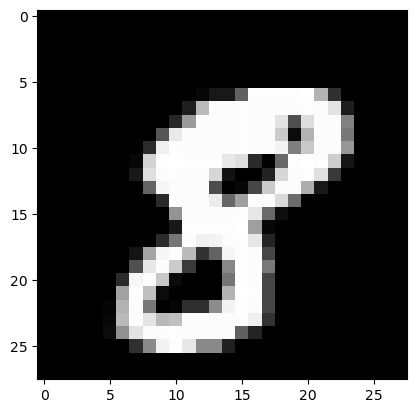

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression

# 加载数据集
digit = pd.read_csv("data/train.csv")
plt.imshow(digit.iloc[10, 1:].values.reshape(28, 28), cmap="gray")
plt.show()


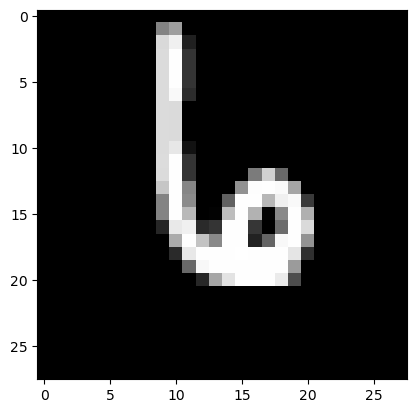

[6]


In [3]:
# 划分训练集和测试集
X = digit.drop("label", axis=1)  # 特征
y = digit["label"]  # 标签

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100)

# 归一化
# 消除量级影响: 排除数值极大对整体数据的影响
# 加速算法收敛：对于梯度下降算法或者基于距离的算法，归一化让所有特征数据处于统一起跑线，避免梯度震荡，提供训练速度和准确度。
preprocessor = MinMaxScaler()
x_train = preprocessor.fit_transform(x_train)
x_test = preprocessor.transform(x_test)

# 模型训练
model = LogisticRegression(max_iter=500)
model.fit(x_train, y_train)

# 模型评估
model.score(x_test, y_test)

# 预测
plt.imshow(digit.iloc[123, 1:].values.reshape(28, 28), cmap="gray")
plt.show()
print(model.predict(digit.iloc[123, 1:].values.reshape(1, -1)))